## Who worked on this part?
Muhammad Azaam Ali: compared all mushroom models on the same data, chose the final model and its threshold, scored it on the test set and analysed its mistakes.

# Mushroom: comparing the models

Every model notebook saved its trained pipeline in `models/`. Here we put them side by side and make the final choices:
1. **compare** all models on the validation set with the same metrics
2. **choose the threshold** of the best model, also on the validation set
3. **score the final model once on the test set**: the first time the test set is used, so the only honest estimate for new mushrooms
4. **error analysis**: which poisonous mushrooms does the final model still miss, and why?

The rule we follow: every choice (model, threshold) is made on validation. The test set only *measures* the choice; if we chose with it, its score would be too optimistic.

## Load the data and the models

In [1]:
import json
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# walk up from where the notebook runs to the repo root, so the data path works on every machine
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'Mushroom' / 'datasets').is_dir())
MUSHROOM = ROOT / 'Mushroom'
DATA = MUSHROOM / 'datasets'

val_df = pd.read_csv(DATA / 'val.csv')
test_df = pd.read_csv(DATA / 'test.csv')
X_val, y_val = val_df.drop(columns='is_poisonous'), val_df['is_poisonous']
X_test, y_test = test_df.drop(columns='is_poisonous'), test_df['is_poisonous']

models = {
    'logistic regression': joblib.load(MUSHROOM / 'models' / 'logreg.pkl'),
    'random forest': joblib.load(MUSHROOM / 'models' / 'random_forest.pkl'),
    'hist gradient boosting': joblib.load(MUSHROOM / 'models' / 'hist_gradient_boosting.pkl'),
}
list(models)

['logistic regression', 'random forest', 'hist gradient boosting']

## Results from the other notebooks
PyCaret and AWS ran in other environments, so we read their saved results instead of their models.

**PyCaret** (`3.1MushroomPyCaret.ipynb`): cross-validated scores on the training data, all models with default settings. This is what made us pick the random forest and gradient boosting for tuning.

In [2]:
pycaret = pd.read_csv(MUSHROOM / 'results' / 'pycaret_leaderboard.csv', index_col=0)
pycaret[['Model', 'AUC', 'Recall', 'Prec.', 'Accuracy']].round(3)

,Model,AUC,Recall,Prec.,Accuracy
rf,Random Forest Classifier,0.831,0.601,0.804,0.793
et,Extra Trees Classifier,0.802,0.604,0.716,0.759
gbc,Gradient Boosting Classifier,0.776,0.445,0.799,0.747
knn,K Neighbors Classifier,0.751,0.528,0.712,0.740
ada,Ada Boost Classifier,0.707,0.377,0.670,0.693
lr,Logistic Regression,0.698,0.362,0.681,0.694
ridge,Ridge Classifier,0.697,0.346,0.694,0.694
lda,Linear Discriminant Analysis,0.697,0.352,0.689,0.694
dt,Decision Tree Classifier,0.672,0.589,0.594,0.692
nb,Naive Bayes,0.666,0.196,0.738,0.670


**AWS** (`3.5MushroomSageMaker.ipynb`): the tuning job on SageMaker saves its best result in `results/sagemaker_best.json`. That notebook still has to run on AWS, so the cell below only shows something once the file exists.

In [3]:
sagemaker_file = MUSHROOM / 'results' / 'sagemaker_best.json'
if sagemaker_file.exists():
    sagemaker = json.loads(sagemaker_file.read_text())
    print(sagemaker['hyperparameters'])
    print(sagemaker['metrics'])
else:
    print('not run on AWS yet: no', sagemaker_file.name)

{'_tuning_objective_metric': 'val_auc', 'max-features': '0.7986555812281954', 'min-samples-leaf': '1', 'model': '"rf"', 'n-estimators': '593', 'sagemaker_container_log_level': '20', 'sagemaker_estimator_class_name': '"SKLearn"', 'sagemaker_estimator_module': '"sagemaker.sklearn.estimator"', 'sagemaker_job_name': '"mushroom-rf-2026-10-10-21-20-30-577"', 'sagemaker_program': '"train.py"', 'sagemaker_region': '"us-east-1"', 'sagemaker_submit_directory': '"s3://sagemaker-us-east-1-349633751165/mushroom-rf-2026-10-10-21-20-30-577/source/sourcedir.tar.gz"'}
{'ObjectiveMetric': 0.8500000238418579, 'cv_auc_std': 0.02199999988079071, 'test_auc': 0.8421000242233276, 'test_precision': 0.5048999786376953, 'test_accuracy': 0.628000020980835, 'test_recall': 0.9014000296592712, 'val_precision': 0.5038999915122986, 'threshold': 0.18709999322891235, 'test_f1': 0.6473000049591064, 'val_auc': 0.8500000238418579, 'val_recall': 0.9014000296592712, 'train_auc': 1.0, 'cv_auc': 0.8263000249862671, 'test_pr_au

## Step 1: compare the models on validation
The same `evaluate()` as in the model notebooks, plus one extra metric:
- **PR-AUC** (average precision): the area under the precision-recall curve. Like ROC-AUC it doesn't depend on the threshold, but it focuses on the poisonous class: how precise can the model stay while it catches more and more poisonous mushrooms? That is exactly our trade-off.

In [4]:
from sklearn.metrics import roc_auc_score, average_precision_score, recall_score, precision_score, f1_score, accuracy_score

def evaluate(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {
        'roc_auc': roc_auc_score(y_true, proba),
        'pr_auc': average_precision_score(y_true, proba),
        'recall': recall_score(y_true, pred),
        'precision': precision_score(y_true, pred, zero_division=0),
        'f1': f1_score(y_true, pred),
        'accuracy': accuracy_score(y_true, pred),
    }

# predicted chance of poisonous for every validation mushroom, per model
val_proba = {name: model.predict_proba(X_val)[:, 1] for name, model in models.items()}

val_scores = pd.DataFrame({name: evaluate(y_val, proba) for name, proba in val_proba.items()}).T.round(3)
val_scores

,roc_auc,pr_auc,recall,precision,f1,accuracy
logistic regression,0.700,0.662,0.602,0.541,0.570,0.656
random forest,0.852,0.802,0.620,0.822,0.707,0.805
hist gradient boosting,0.829,0.786,0.577,0.770,0.660,0.775


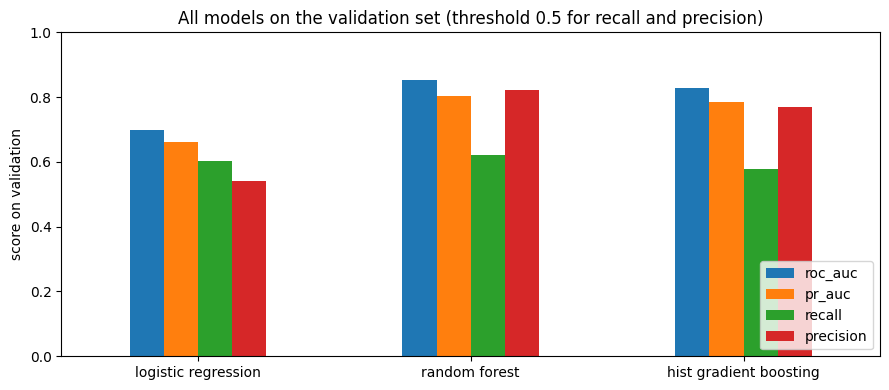

In [5]:
val_scores[['roc_auc', 'pr_auc', 'recall', 'precision']].plot.bar(figsize=(9, 4), rot=0)
plt.ylim(0, 1)
plt.ylabel('score on validation')
plt.title('All models on the validation set (threshold 0.5 for recall and precision)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

The curves show the same comparison at **every** threshold at once:
- **ROC curve**: share of poisonous caught (recall) against share of edible wrongly flagged. The closer to the top-left corner, the better. The diagonal is guessing.
- **Precision-recall curve**: for every recall, how many of the flagged mushrooms are really poisonous. The dashed line is the share of poisonous mushrooms (38%): the precision you'd get by flagging at random.

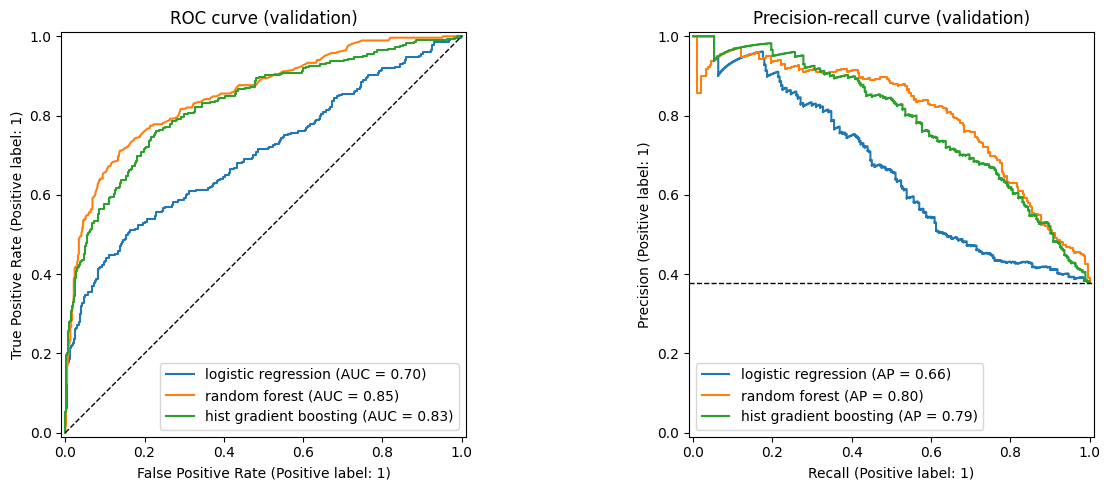

In [6]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, proba in val_proba.items():
    RocCurveDisplay.from_predictions(y_val, proba, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_val, proba, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], 'k--', linewidth=1)
axes[1].axhline(y_val.mean(), color='k', linestyle='--', linewidth=1)
axes[0].set_title('ROC curve (validation)')
axes[1].set_title('Precision-recall curve (validation)')
plt.tight_layout()
plt.show()

### What this tells us
The **random forest** wins on every metric on validation: ROC-AUC 0.852 against 0.829 (gradient boosting) and 0.700 (logistic regression), and PR-AUC 0.802 against 0.786 and 0.662. At threshold 0.5 it also has the highest recall (0.62), precision (0.82) and accuracy (0.81).

On the curves the forest is above gradient boosting almost everywhere. Gradient boosting is only slightly ahead at the very strict end (the few mushrooms each model is most sure about, recall below about 0.35) and practically equal around recall 0.9. For the part we care about, catching most poisonous mushrooms, the forest is as good or better.

Logistic regression stays far behind on the whole curve: it can only add up one weight per feature and can't learn combinations of features, which is where the signal in this data sits.

## Step 2: choose the threshold
At threshold 0.5 the best model still calls a big part of the poisonous mushrooms edible. For a mushroom app that's the dangerous mistake, so we **fix the recall we want first** and accept the precision that comes with it.

How we pick it: `precision_recall_curve` gives precision and recall for every possible threshold. We take the **highest threshold that still catches at least the target share** of the poisonous validation mushrooms. Higher threshold = fewer edible mushrooms wrongly flagged, so the highest one that meets the target is the best one.

(`precision` and `recall` have one value more than `thresholds`, the end point of the curve, so we drop the last one with `[:-1]` to line them up.)

In [7]:
from sklearn.metrics import precision_recall_curve

final_name = val_scores['roc_auc'].idxmax()
final_model = models[final_name]
print('final model:', final_name)

precision, recall, thresholds = precision_recall_curve(y_val, val_proba[final_name])

def threshold_for(target_recall):
    return thresholds[recall[:-1] >= target_recall].max()

# what different recall targets would cost on validation
trade_off = pd.DataFrame({
    f'recall >= {target}': {'threshold': threshold_for(target), **evaluate(y_val, val_proba[final_name], threshold_for(target))}
    for target in [0.80, 0.85, 0.90, 0.95]
}).T[['threshold', 'recall', 'precision', 'accuracy']].round(3)
trade_off

final model: random forest


,threshold,recall,precision,accuracy
recall >= 0.8,0.310,0.806,0.631,0.748
recall >= 0.85,0.253,0.852,0.572,0.703
recall >= 0.9,0.197,0.901,0.512,0.637
recall >= 0.95,0.150,0.951,0.470,0.575


We choose a **recall target of 0.90**: 9 out of 10 poisonous mushrooms are flagged. This is also the default target in our deployment code (`model/train.py`), so the hosted model behaves the same way.

The plot shows the price: recall and precision against the threshold, with our choice as a vertical line.

threshold: 0.197


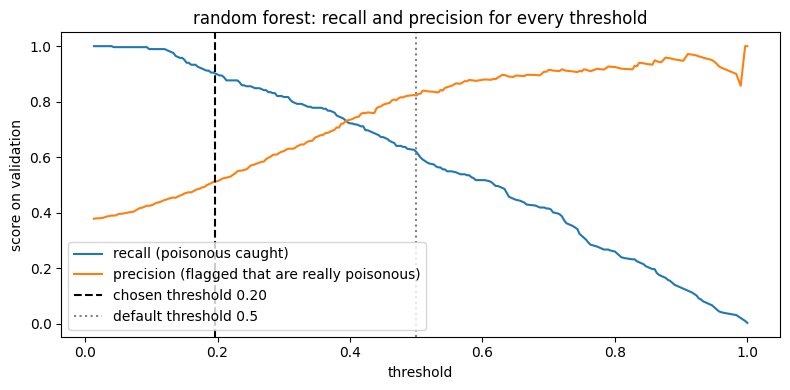

In [8]:
TARGET_RECALL = 0.90
threshold = threshold_for(TARGET_RECALL)
print('threshold:', round(threshold, 3))

plt.figure(figsize=(8, 4))
plt.plot(thresholds, recall[:-1], label='recall (poisonous caught)')
plt.plot(thresholds, precision[:-1], label='precision (flagged that are really poisonous)')
plt.axvline(threshold, color='k', linestyle='--', label=f'chosen threshold {threshold:.2f}')
plt.axvline(0.5, color='grey', linestyle=':', label='default threshold 0.5')
plt.xlabel('threshold')
plt.ylabel('score on validation')
plt.title(f'{final_name}: recall and precision for every threshold')
plt.legend()
plt.tight_layout()
plt.show()

### What this tells us
To catch 90% of the poisonous mushrooms the threshold drops from 0.5 to 0.20. That costs a lot: precision falls from 0.82 to 0.51 and accuracy from 0.81 to 0.64. In plain words: out of every 10 mushrooms the app flags as poisonous, only about **5 really are poisonous**; the other 5 are edible mushrooms flagged to be safe.

We accept that because the two mistakes are not equally bad. Calling an edible mushroom poisonous means someone throws away a good mushroom; calling a poisonous mushroom edible can mean someone gets poisoned.

A target of 0.95 would be safer still, but the threshold would drop to 0.15 and precision to 0.47, accuracy to 0.58: more than half of the flagged mushrooms would be edible. With a model at AUC 0.85, every extra percent of recall gets more expensive. We keep 0.90, which is also the default in our deployment code.

## Step 3: the test set, once
Model and threshold are now fixed. Only now do we score on the test set, which no model and no choice has seen.

We also show the ROC-AUC of the other two models on test. That doesn't change the choice (it was made on validation); it only checks that the ranking holds on new data.

In [9]:
test_proba = final_model.predict_proba(X_test)[:, 1]

pd.DataFrame({
    f'{final_name} (val, threshold {threshold:.2f})': evaluate(y_val, val_proba[final_name], threshold),
    f'{final_name} (test, threshold {threshold:.2f})': evaluate(y_test, test_proba, threshold),
}).T.round(3)

,roc_auc,pr_auc,recall,precision,f1,accuracy
"random forest (val, threshold 0.20)",0.852,0.802,0.901,0.512,0.653,0.637
"random forest (test, threshold 0.20)",0.832,0.774,0.898,0.501,0.643,0.623


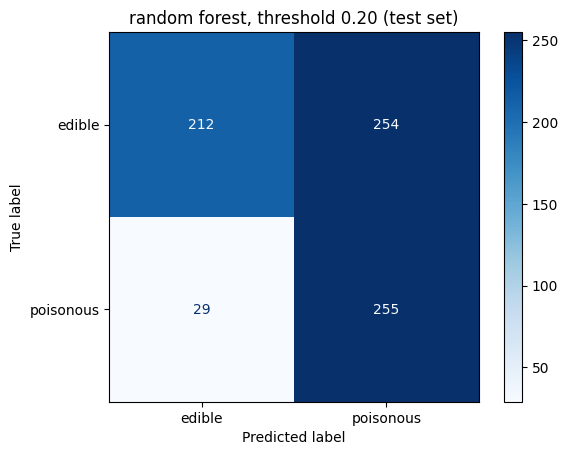

logistic regression       0.700
random forest             0.832
hist gradient boosting    0.816
Name: test roc_auc, dtype: float64

In [10]:
from sklearn.metrics import ConfusionMatrixDisplay

test_pred = (test_proba >= threshold).astype(int)
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=['edible', 'poisonous'], cmap='Blues')
plt.title(f'{final_name}, threshold {threshold:.2f} (test set)')
plt.show()

# does the ranking of the models hold on new data?
pd.Series({name: roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]) for name, model in models.items()}, name='test roc_auc').round(3)

### What this tells us
The test scores are close to validation: ROC-AUC 0.832 against 0.852, accuracy 0.62 against 0.64. A small drop is normal, because the model and threshold were chosen on validation, so validation is slightly optimistic. The test set is the honest number.

Test recall is 0.898: just under the 0.90 target (255 of the 284 poisonous test mushrooms caught, 29 missed). The threshold was chosen on only 284 poisonous validation mushrooms, so one or two mushrooms more or less above the line change the recall by almost 0.01. On new rows it moves a little, which is why a target is never a hard guarantee.

The model ranking holds on test: random forest 0.832, gradient boosting 0.816, logistic regression 0.700.

## Step 4: error analysis
Which poisonous mushrooms does the final model still call edible (**false negatives**)? We sort every test mushroom into the four outcomes of the confusion matrix and compare the groups.

Ideas from the EDA and cleaning to check:
- **missing values**: are the missed ones the mushrooms with the most gaps (`n_missing`)?
- **size**: do they look like the typical edible mushroom?
- **the suspicious groups**: stemless mushrooms (almost all poisonous) and giant caps above 40 cm (almost all edible), where we found likely flipped labels

In [11]:
errors = X_test.copy()
errors['is_poisonous'] = y_test.values
errors['proba'] = test_proba
errors['n_missing'] = (X_test == 'missing').sum(axis=1)  # empty categories, filled with 'missing' in cleaning
errors['stemless'] = errors['stem_surface'] == 'f'
errors['giant'] = errors['cap_diameter_cm'] > 40

real = errors['is_poisonous'] == 1
flagged = test_pred == 1
errors['outcome'] = np.select(
    [real & ~flagged, real & flagged, ~real & flagged],
    ['missed poisonous (FN)', 'caught poisonous (TP)', 'edible flagged (FP)'],
    default='edible correct (TN)',
)

errors.groupby('outcome').agg(
    mushrooms=('proba', 'size'),
    mean_proba=('proba', 'mean'),
    n_missing=('n_missing', 'mean'),
    cap_diameter_cm=('cap_diameter_cm', 'mean'),
    stem_width_mm=('stem_width_mm', 'mean'),
    share_stemless=('stemless', 'mean'),
    share_giant=('giant', 'mean'),
).round(2)

,mushrooms,mean_proba,n_missing,cap_diameter_cm,stem_width_mm,share_stemless,share_giant
outcome,,,,,,,
caught poisonous (TP),255,0.62,2.39,5.56,10.32,0.04,0.0
edible correct (TN),212,0.12,2.38,7.38,15.08,0.00,0.0
edible flagged (FP),254,0.36,2.50,6.48,12.26,0.00,0.0
missed poisonous (FN),29,0.11,2.38,8.90,15.91,0.00,0.0


The missed poisonous mushrooms themselves, lowest predicted chance first: the ones the model was most sure were edible.

In [12]:
missed = errors[errors['outcome'] == 'missed poisonous (FN)'].sort_values('proba')
missed[['proba', 'n_missing', 'cap_diameter_cm', 'stem_width_mm', 'stem_surface', 'cap_shape', 'ring_type', 'gill_color']].round(2)

,proba,n_missing,cap_diameter_cm,stem_width_mm,stem_surface,cap_shape,ring_type,gill_color
511,0.01,2,5.60,9.10,s,f,f,missing
458,0.02,3,8.29,16.66,s,x,f,missing
616,0.03,1,6.16,5.51,t,x,l,n
193,0.03,2,8.40,16.97,s,f,f,w
541,0.06,3,8.37,16.43,missing,f,f,missing
570,0.06,2,6.32,11.17,s,f,e,w
627,0.06,3,17.65,22.79,missing,f,f,k
219,0.08,1,6.54,13.02,s,x,f,y
585,0.09,2,7.16,13.21,missing,x,f,r
689,0.09,2,8.73,18.12,y,p,p,missing


### What this tells us
- **Not the gaps.** The 29 missed poisonous mushrooms have on average 2.4 empty categories, the same as the edible mushrooms the model got right (2.4) and the caught poisonous ones (2.4).
- **Not the suspicious groups.** None of them is stemless or has a giant cap.
- **They look like edible mushrooms.** Their average cap (8.9 cm) and stem width (15.9 mm) are close to the correctly classified edible ones (7.4 cm, 15.1 mm) and far from the caught poisonous ones (5.6 cm, 10.3 mm). The model is very sure they are edible: their average predicted chance is 0.11, about the same as for the real edible ones (0.12), against 0.62 for the caught poisonous ones.

So these are poisonous mushrooms that look edible in every column the dataset has. Some are probably **flipped labels** (edible mushrooms labelled poisonous, as the assignment warns); others are species that are poisonous but simply can't be told apart from edible ones with these 10 features. No model can catch those: there is nothing in the data that separates them, and a model that did "catch" them on training data would only be memorising.

## Conclusion
The final model is the **random forest** (tuned in `3.2MushroomRandomForest.ipynb`): it has the best ROC-AUC and PR-AUC on validation, it is as good or better than gradient boosting on the part of the curves we care about, and the ranking holds on test.

With the threshold set to catch 90% of the poisonous validation mushrooms (0.20), it scores on the **test set**: ROC-AUC 0.832, recall 0.898, precision 0.50, accuracy 0.62. About half of the mushrooms it flags are really edible. We accept that because missing a poisonous mushroom is far worse than throwing away an edible one.

The 29 poisonous test mushrooms it still misses don't have more gaps and aren't in the stemless or giant groups: they look like edible mushrooms in every feature, and the model is confident they are edible. Part of them are likely flipped labels, part are poisonous species these features can't separate.

What could still help: more rows, and features the dataset lost (the original UCI data had more columns and no gaps). What can't be fixed is the label noise: with flipped labels in train and test, no model can reach a perfect score, and tuning has already stopped giving real gains for all three models (every improvement was within the noise between folds).